In [19]:
import os
import math

# if you've setup your environment, importing these libraries should not throw an error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import librosa
import librosa.display
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter
import IPython.display as ipd

from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')


PATH_TO_DATASET = '/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development'

In [3]:
metadata = pd.read_csv(os.path.join(PATH_TO_DATASET, "metadata.csv"))

In [3]:
metadata.columns.to_list()

['filename',
 'target_classes',
 'recording_device',
 'device_placement',
 'recording_environment',
 'scene_description',
 'license',
 'collector_id',
 'non_target_classes']

In [4]:
annotations = pd.read_csv(os.path.join(PATH_TO_DATASET, "annotations.csv"))
annotations.columns.to_list()

['filename',
 'annotator_id',
 'annotation',
 'onset',
 'offset',
 'is_own_recording']

In [5]:
annotations.head(10)

,filename,annotator_id,annotation,onset,offset,is_own_recording
0,000112.wav,2190518039615423109192646528977018723001939610...,footsteps,13.060211,13.315831,False
1,000695.wav,4496809211053681637690999252976315563042618669...,door_open_close,1.508440,2.061877,False
2,000488.wav,7535443191697509271271535104115945129183028445...,microwave,4.833705,25.929958,True
3,005087.wav,4496809211053681637690999252976315563042618669...,keyboard_typing,0.337356,18.230374,False
4,005465.wav,7618427328765435143030208879017391647684958822...,running_water,5.254437,15.088430,True
5,005684.wav,9877130198842003339025240559850474592336536376...,wardrobe_drawer_open_close,1.007815,1.315758,False
6,000751.wav,5727477084251462872940252873008114897530837887...,phone_ringing,23.893084,26.560000,False
7,004764.wav,1037221425498305099935969705524893126215865241...,cutlery_dishes,27.511767,28.376917,False
8,000702.wav,7578529618691803451076682762345226062747344659...,cutlery_dishes,9.460196,14.521962,True
9,001729.wav,9931757987855761757854106089782104284187009332...,cutlery_dishes,13.682257,15.571376,True


In [6]:
# annotations.set_index('filename', inplace=True)

In [7]:
annotations.head()

,filename,annotator_id,annotation,onset,offset,is_own_recording
0,000112.wav,2190518039615423109192646528977018723001939610...,footsteps,13.060211,13.315831,False
1,000695.wav,4496809211053681637690999252976315563042618669...,door_open_close,1.508440,2.061877,False
2,000488.wav,7535443191697509271271535104115945129183028445...,microwave,4.833705,25.929958,True
3,005087.wav,4496809211053681637690999252976315563042618669...,keyboard_typing,0.337356,18.230374,False
4,005465.wav,7618427328765435143030208879017391647684958822...,running_water,5.254437,15.088430,True


In [25]:
annotations[annotations['filename'] == '003680.wav']

,filename,annotator_id,annotation,onset,offset,is_own_recording
8335,003680.wav,9215010370808489209735735142344412904008678513...,door_open_close,8.131185,11.722874,False
25647,003680.wav,9215010370808489209735735142344412904008678513...,running_water,12.658210,27.548754,False
28436,003680.wav,4143865275236641701175714500407992183001182566...,running_water,12.648454,27.411332,False
29096,003680.wav,4143865275236641701175714500407992183001182566...,door_open_close,10.457833,11.267410,False


In [9]:
# annotations.loc[annotations['is_own_recording'] == True]
# study_case = annotations[annotations['filename'] == '003680.wav']

In [30]:
# case_study_3680 = annotations.loc[(annotations['filename'] == '003680.wav') & (annotations['is_own_recording'] == True)]
case_study_3680 = annotations.loc[(annotations['filename'] == '003680.wav')]
case_study_3680

,filename,annotator_id,annotation,onset,offset,is_own_recording
8335,003680.wav,9215010370808489209735735142344412904008678513...,door_open_close,8.131185,11.722874,False
25647,003680.wav,9215010370808489209735735142344412904008678513...,running_water,12.658210,27.548754,False
28436,003680.wav,4143865275236641701175714500407992183001182566...,running_water,12.648454,27.411332,False
29096,003680.wav,4143865275236641701175714500407992183001182566...,door_open_close,10.457833,11.267410,False


In [29]:
metadata[metadata["filename"] == "003680.wav"]

,filename,target_classes,recording_device,device_placement,recording_environment,scene_description,license,collector_id,non_target_classes
972,003680.wav,running_water;door_open_close,iPhone 17 Pro Max,mobile,bathroom,I walked into the bathroom and closed the door...,"CC-BY 4.0 (Attribution License), Author: Mykha...",521aa0e58c49977c,ventilation_noise


In [32]:
# metadata.loc[metadata["filename"] == "003680.wav", "scene_description"]

In [31]:
annotations.loc[annotations['filename'] == '003680.wav'].sort_values(by=['annotator_id','onset'])

,filename,annotator_id,annotation,onset,offset,is_own_recording
29096,003680.wav,4143865275236641701175714500407992183001182566...,door_open_close,10.457833,11.267410,False
28436,003680.wav,4143865275236641701175714500407992183001182566...,running_water,12.648454,27.411332,False
8335,003680.wav,9215010370808489209735735142344412904008678513...,door_open_close,8.131185,11.722874,False
25647,003680.wav,9215010370808489209735735142344412904008678513...,running_water,12.658210,27.548754,False


In [52]:
import librosa
import IPython.display as ipd

# Load the audio file
file_path = '/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development/MLPC2026_dataset_development_audio/003680.wav'  
audio, sr = librosa.load(file_path, sr=None)  # sr=None keeps original sample rate

# Play the audio in Jupyter notebook
ipd.Audio(audio, rate=sr)

In [50]:
# # Load the audio file
# file_path = '/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development/MLPC2026_dataset_development_audio/003680.wav'  
# audio, sr = librosa.load(file_path, sr=None)  # sr=None keeps original sample rate

# # Play the audio in Jupyter notebook
# ipd.Audio(audio, rate=sr)

# # Create a figure with two subplots
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))

# # Plot 1: Waveform
# librosa.display.waveshow(audio, sr=sr, ax=ax1, color='blue', alpha=0.6)
# ax1.set_title('Waveform (Amplitude over Time)', fontsize=14, fontweight='bold')
# ax1.set_xlabel('Time (seconds)', fontsize=12)
# ax1.set_ylabel('Amplitude', fontsize=12)
# ax1.grid(True, alpha=0.3)

# # Plot 2: Spectrogram
# # Compute Short-Time Fourier Transform (STFT)
# D = librosa.stft(audio)
# S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

# # Display spectrogram
# img = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='hz', ax=ax2, cmap='viridis')
# ax2.set_title('Spectrogram (Frequency over Time)', fontsize=14, fontweight='bold')
# ax2.set_xlabel('Time (seconds)', fontsize=12)
# ax2.set_ylabel('Frequency (Hz)', fontsize=12)
# ax2.grid(True, alpha=0.3)

# # Add colorbar
# cbar = plt.colorbar(img, ax=ax2, format='%+2.0f dB')
# cbar.set_label('Intensity (dB)', fontsize=12)

# plt.tight_layout()
# plt.show()

# # Print audio information
# duration = len(audio) / sr
# print(f"\nAudio Information:")
# print(f"Sample rate: {sr} Hz")
# print(f"Duration: {duration:.2f} seconds")
# print(f"Number of samples: {len(audio)}")
# print(f"Number of channels: {1 if len(audio.shape) == 1 else audio.shape[1]}")

In [33]:
print(metadata.loc[metadata["filename"] == "003680.wav", "scene_description"].iloc[0])

I walked into the bathroom and closed the door. I turned the water on, then turned it off and left.


### Annotation quality 

In [43]:
for file, group in annotations.groupby('filename'):
    print(f"File: {file}")
    print(f"  Number of annotations: {len(group)}")
    print(f"  Annotations: {group['annotation'].tolist()}")
    print(f"  Time range: {group['onset'].min():.2f}s - {group['offset'].max():.2f}s")
    print("-" * 50)

File: 000001.wav
  Number of annotations: 10
  Annotations: ['phone_ringing', 'keyboard_typing', 'phone_ringing', 'phone_ringing', 'phone_ringing', 'keyboard_typing', 'keyboard_typing', 'keyboard_typing', 'phone_ringing', 'phone_ringing']
  Time range: 0.00s - 31.21s
--------------------------------------------------
File: 000002.wav
  Number of annotations: 7
  Annotations: ['door_open_close', 'door_open_close', 'footsteps', 'door_open_close', 'door_open_close', 'footsteps', 'door_open_close']
  Time range: 1.30s - 28.83s
--------------------------------------------------
File: 000003.wav
  Number of annotations: 1
  Annotations: ['light_switch']
  Time range: 4.58s - 4.97s
--------------------------------------------------
File: 000004.wav
  Number of annotations: 22
  Annotations: ['light_switch', 'footsteps', 'footsteps', 'keychain', 'light_switch', 'door_open_close', 'keychain', 'door_open_close', 'keychain', 'light_switch', 'footsteps', 'footsteps', 'footsteps', 'door_open_close'

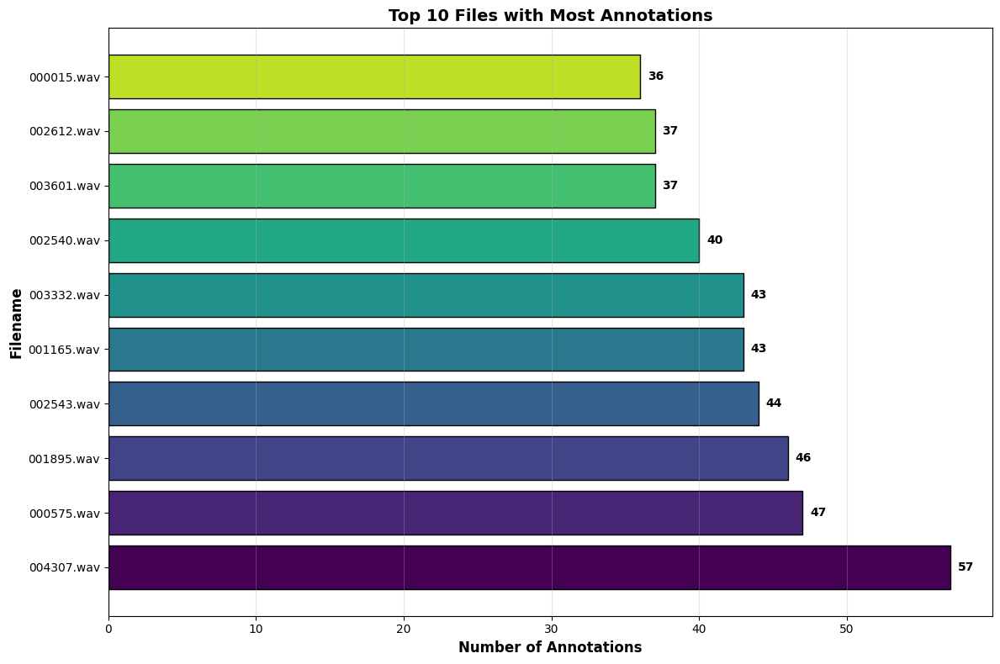


Top 10 Files Summary:
Total annotations in top 10 files: 430
Average per top file: 43.00


In [52]:

# Calculate annotations per file and get top 10
annotations_per_file = annotations.groupby('filename').size().sort_values(ascending=False).head(10)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))
colors = plt.cm.viridis(np.linspace(0, 0.9, 10))
bars = plt.barh(range(len(annotations_per_file)), annotations_per_file.values, color=colors, edgecolor='black')

plt.yticks(range(len(annotations_per_file)), annotations_per_file.index, fontsize=10)
plt.xlabel('Number of Annotations', fontsize=12, fontweight='bold')
plt.ylabel('Filename', fontsize=12, fontweight='bold')
plt.title('Top 10 Files with Most Annotations', fontsize=14, fontweight='bold')

# Add value labels on the bars
for i, (bar, value) in enumerate(zip(bars, annotations_per_file.values)):
    plt.text(value + 0.5, bar.get_y() + bar.get_height()/2, 
             f'{value}', va='center', fontsize=10, fontweight='bold')

plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# Print summary
print(f"\nTop 10 Files Summary:")
print(f"Total annotations in top 10 files: {annotations_per_file.sum()}")
print(f"Average per top file: {annotations_per_file.mean():.2f}")

In [46]:
annotations.loc[annotations['filename'] == '004307.wav'].sort_values(by=['annotator_id','onset'])

,filename,annotator_id,annotation,onset,offset,is_own_recording
4578,004307.wav,3406720903689984992758328668425300874060287046...,footsteps,0.727623,8.654888,True
20112,004307.wav,3406720903689984992758328668425300874060287046...,keychain,8.731480,14.016323,True
17188,004307.wav,3406720903689984992758328668425300874060287046...,door_open_close,16.122601,18.573543,True
27388,004307.wav,3406720903689984992758328668425300874060287046...,keychain,20.067085,23.054170,True
31742,004307.wav,3406720903689984992758328668425300874060287046...,door_open_close,23.283946,24.854081,True
24965,004307.wav,6214305879671816562386676675014820546670572615...,footsteps,0.813333,8.133333,False
29277,004307.wav,6214305879671816562386676675014820546670572615...,keychain,8.607778,9.827778,False
19163,004307.wav,6214305879671816562386676675014820546670572615...,door_open_close,10.708889,17.870741,False
3669,004307.wav,6214305879671816562386676675014820546670572615...,footsteps,18.435556,19.226296,False
9588,004307.wav,6214305879671816562386676675014820546670572615...,keychain,20.412407,21.609815,False


In [47]:
# Load the audio file
file_path = '/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development/MLPC2026_dataset_development_audio/004307.wav'  
audio, sr = librosa.load(file_path, sr=None)  # sr=None keeps original sample rate

# Play the audio in Jupyter notebook
ipd.Audio(audio, rate=sr)

In [48]:
metadata[metadata["filename"] == "004307.wav"]

,filename,target_classes,recording_device,device_placement,recording_environment,scene_description,license,collector_id,non_target_classes
3182,004307.wav,footsteps;keychain;door_open_close;light_switch,iPhone 13,mobile,hallway,"I walk to the door, unlock it using my keys, o...","CC-BY 4.0 (Attribution License), Author: Prana...",f5c82c58e273b5fb,NaN


In [15]:
# metadata["license"].unique()

In [ ]:
print(metadata.loc[metadata["filename"] == "004307.wav", "scene_description"].iloc[0])
print(metadata.loc[metadata["filename"] == "004307.wav", "license"].iloc[0])

I walk to the door, unlock it using my keys, open the door, and turn on the light.
CC-BY 4.0 (Attribution License), Author: Pranavamaniyan Thiagarajan Mohanapriya


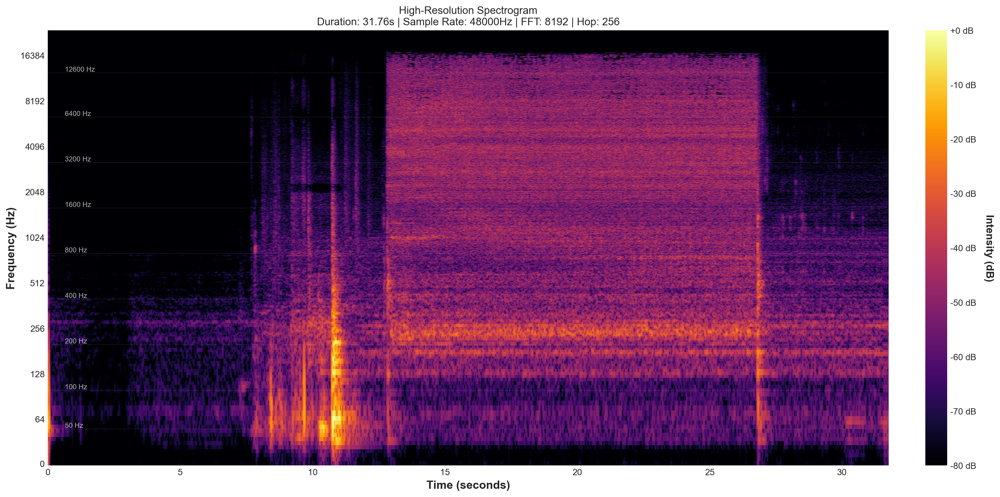


📊 Spectrogram Parameters:
  • FFT window size: 8192 samples (170.7 ms)
  • Hop length: 256 samples (5.3 ms)
  • Frequency resolution: 5.86 Hz/bin
  • Time resolution: 5.3 ms/frame
  • Dynamic range: 0 to --100 dB


In [73]:

# Load audio
file_path = '/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development/MLPC2026_dataset_development_audio/003680.wav'  
audio, sr = librosa.load(file_path, sr=None)

ipd.Audio(audio, rate=sr)

# High-quality parameters
n_fft = 8192  # Very high frequency resolution
hop_length = 256  # High time resolution (overlap of 32x for n_fft=8192)
win_length = 8192

# Compute spectrogram with better windowing
window = 'hann'
D = librosa.stft(audio, n_fft=n_fft, hop_length=hop_length, 
                 win_length=win_length, window=window)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max, top_db=100)


fig, ax = plt.subplots(figsize=(16, 8), dpi=200)
img = librosa.display.specshow(S_db, sr=sr, hop_length=hop_length,
                                x_axis='time', y_axis='log',
                                ax=ax, cmap='inferno',  # 'inferno' has good contrast
                                vmin=-80, vmax=0)

# Enhance visual appearance
ax.set_title('High-Resolution Spectrogram', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Time (seconds)', fontsize=13, fontweight='bold')
ax.set_ylabel('Frequency (Hz)', fontsize=13, fontweight='bold')

# Improve grid
ax.grid(True, alpha=0.2, linestyle='--', linewidth=0.5, which='both')

# Customize colorbar
cbar = plt.colorbar(img, ax=ax, format='%+2.0f dB', fraction=0.046, pad=0.04)
cbar.set_label('Intensity (dB)', fontsize=12, fontweight='bold', rotation=270, labelpad=20)
cbar.ax.tick_params(labelsize=10)

# Add frequency markers for common sounds
freq_markers = [50, 100, 200, 400, 800, 1600, 3200, 6400, 12600]
for freq in freq_markers:
    ax.axhline(y=freq, color='white', linestyle=':', alpha=0.3, linewidth=0.5)
    ax.text(ax.get_xlim()[1] * 0.02, freq, f'{freq} Hz', 
            fontsize=8, color='white', alpha=0.7, va='bottom')

# Add title with audio info
duration = len(audio) / sr
info_text = f'Duration: {duration:.2f}s | Sample Rate: {sr}Hz | FFT: {n_fft} | Hop: {hop_length}'
ax.set_title(f'High-Resolution Spectrogram\n{info_text}', fontsize=12, fontweight='normal')

plt.tight_layout()
plt.show()

print(f"\n📊 Spectrogram Parameters:")
print(f"  • FFT window size: {n_fft} samples ({n_fft/sr*1000:.1f} ms)")
print(f"  • Hop length: {hop_length} samples ({hop_length/sr*1000:.1f} ms)")
print(f"  • Frequency resolution: {sr/n_fft:.2f} Hz/bin")
print(f"  • Time resolution: {hop_length/sr*1000:.1f} ms/frame")
print(f"  • Dynamic range: 0 to -{S_db.min():.0f} dB")

In [5]:
annotations.head()

,filename,annotator_id,annotation,onset,offset,is_own_recording
0,000112.wav,2190518039615423109192646528977018723001939610...,footsteps,13.060211,13.315831,False
1,000695.wav,4496809211053681637690999252976315563042618669...,door_open_close,1.508440,2.061877,False
2,000488.wav,7535443191697509271271535104115945129183028445...,microwave,4.833705,25.929958,True
3,005087.wav,4496809211053681637690999252976315563042618669...,keyboard_typing,0.337356,18.230374,False
4,005465.wav,7618427328765435143030208879017391647684958822...,running_water,5.254437,15.088430,True


In [6]:
metadata.head()

,filename,target_classes,recording_device,device_placement,recording_environment,scene_description,license,collector_id,non_target_classes
0,003075.wav,keyboard_typing;keychain,IPhone Xr,static,office,I was working on my laptop and playing with ke...,CC0 (Public Domain Dedication),04d6c4738cd1814c,fan_working;hand_moving_on_table
1,001117.wav,footsteps,Iphone 15 Pro,mobile,office,"I was walking and recorded a bird singing, car...",CC0 (Public Domain Dedication),f125c6e647565367,bird_sing;car
2,001982.wav,footsteps;door_open_close;cutlery_dishes,Surface Pro 8,static,living_room,I went to the patio door and opened it. I went...,CC0 (Public Domain Dedication),23f33a22e31d3072,NaN
3,003018.wav,footsteps;toilet_flushing;running_water,IPhone 15 Pro Max,static,bathroom,I flushed the toilet and walked to the sink. I...,CC0 (Public Domain Dedication),0ada14bcb30cabc5,towel_rustling;coughing;toilet_tank_refilling
4,002291.wav,light_switch;footsteps,Iphone 15 pro,mobile,bedroom;kitchen;bathroom,I turn on light switches around rooms while wa...,CC0 (Public Domain Dedication),9141efc68a18c882,NaN


In [7]:


print("="*50)
print("DATA OVERVIEW")
print("="*50)
print(f"\nAnnotations shape: {annotations.shape}")
print(f"Metadata shape: {metadata.shape}")
print(f"\nUnique files: {annotations['filename'].nunique()}")
print(f"Unique annotators: {annotations['annotator_id'].nunique()}")
print(f"Unique annotation classes: {annotations['annotation'].nunique()}")

DATA OVERVIEW

Annotations shape: (37419, 6)
Metadata shape: (3656, 9)

Unique files: 3656
Unique annotators: 602
Unique annotation classes: 15


In [8]:
print(f"\nAnnotation classes:\n{annotations['annotation'].value_counts().head(10)}")


Annotation classes:
annotation
footsteps                     6824
door_open_close               4550
cutlery_dishes                4500
keychain                      2951
keyboard_typing               2647
phone_ringing                 2617
wardrobe_drawer_open_close    2574
running_water                 2375
light_switch                  2321
window_open_close             1555
Name: count, dtype: int64


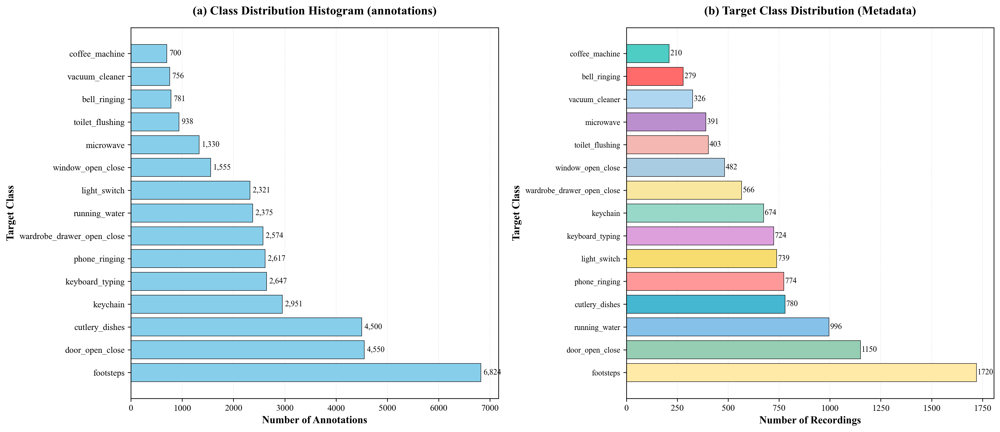

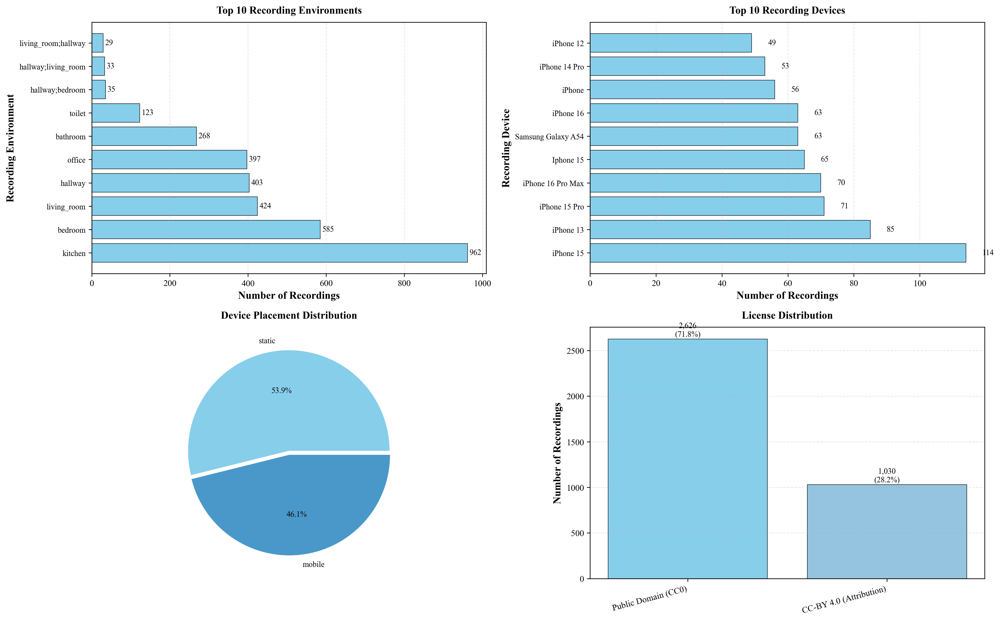

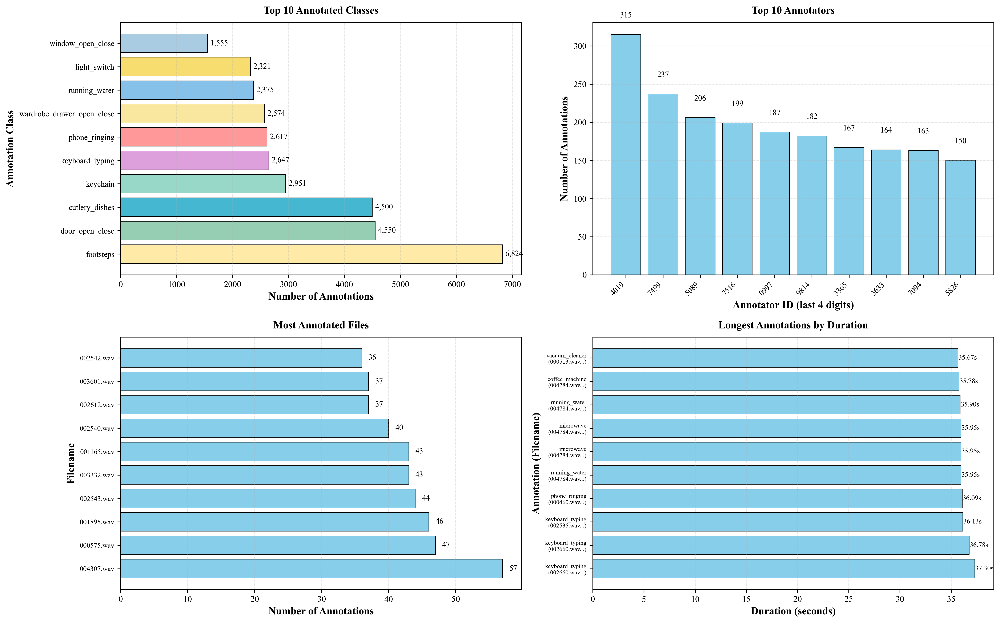

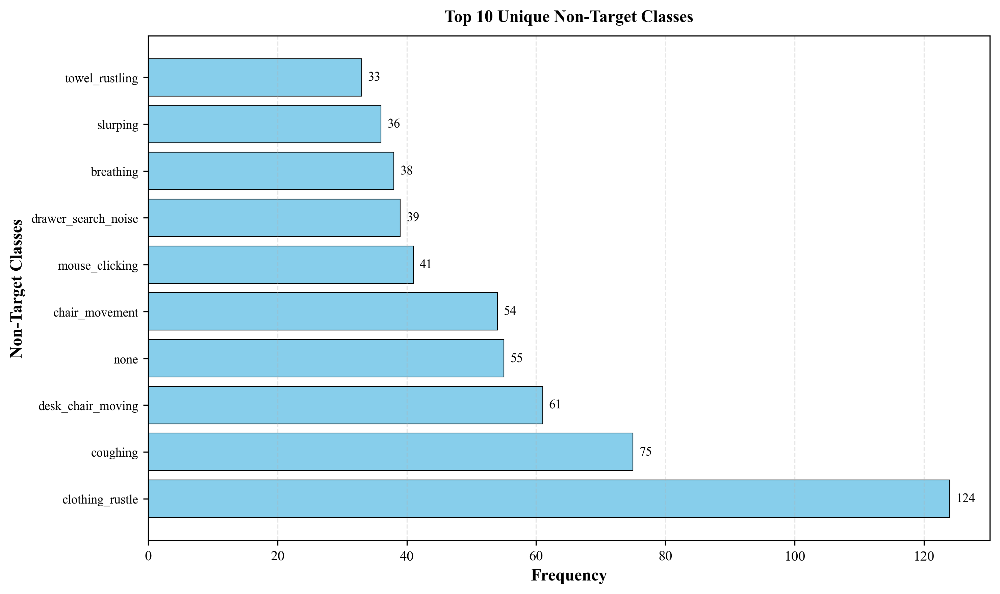

DATASET SUMMARY STATISTICS

Total annotations: 37,419
Total unique files: 3,656
Total unique annotators: 602
Total unique classes: 15

Total recordings (metadata): 3,656
Total unique recording devices: 369
Total unique environments: 123

TOP 5 MOST FREQUENT CLASSES
1. footsteps: 6,824 annotations (18.2%)
2. door_open_close: 4,550 annotations (12.2%)
3. cutlery_dishes: 4,500 annotations (12.0%)
4. keychain: 2,951 annotations (7.9%)
5. keyboard_typing: 2,647 annotations (7.1%)

LICENSE INFORMATION
Public Domain (CC0): 2626 recordings (71.8%)
CC-BY 4.0 (Attribution): 1030 recordings (28.2%)


In [49]:
# style
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'figure.figsize': (10, 6)
})

# Color mapping 
color_mapping = {
    'bell_ringing': '#FF6B6B',
    'coffee_machine': '#4ECDC4',
    'cutlery_dishes': '#45B7D1',
    'door_open_close': '#96CEB4',
    'footsteps': '#FFEAA7',
    'keyboard_typing': '#DDA0DD',
    'keychain': '#98D8C8',
    'light_switch': '#F7DC6F',
    'microwave': '#BB8FCE',
    'phone_ringing': '#FF9999',
    'running_water': '#85C1E9',
    'toilet_flushing': '#F5B7B1',
    'vacuum_cleaner': '#AED6F1',
    'wardrobe_drawer_open_close': '#F9E79F',
    'window_open_close': '#A9CCE3'
}

SKY_BLUE = '#87CEEB'

# =============================
# 1. CLASS DISTRIBUTION - 
# =============================

# Get class distribution from annotations
class_dist = annotations['annotation'].value_counts()
class_dist_df = class_dist.reset_index()
class_dist_df.columns = ['class', 'count']

# Get colors for each annotation based on its class (preserved for potential use)
scatter_colors = [color_mapping.get(cls, '#808080') for cls in annotations['annotation']]

# Create figure for class distribution
fig = plt.figure(figsize=(16, 7))

# Subplot 1: Histogram
ax1 = plt.subplot(1, 2, 1)
bars = ax1.barh(class_dist_df['class'], class_dist_df['count'], color=SKY_BLUE, 
                edgecolor='black', linewidth=0.5)
ax1.set_xlabel('Number of Annotations', fontweight='bold', fontsize=12)
ax1.set_ylabel('Target Class', fontweight='bold', fontsize=12)
ax1.set_title('(a) Class Distribution Histogram (annotations)', fontweight='bold', fontsize=14, pad=15)

# Add value labels
for i, (bar, count) in enumerate(zip(bars, class_dist_df['count'])):
    ax1.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2, 
             f'{int(count):,}', va='center', ha='left', fontsize=9)
ax1.grid(True, axis='x', alpha=0.3, linestyle='--', linewidth=0.5)
ax1.set_axisbelow(True)

# Subplot 2: Target class distribution from metadata (bar plot)

# Extract and count unique target classes from metadata.csv
all_target_classes = []
for classes in metadata['target_classes'].dropna():
    if isinstance(classes, str):
        if ';' in classes:
            all_target_classes.extend([c.strip() for c in classes.split(';')])
        else:
            all_target_classes.append(classes.strip())

target_class_counts = pd.Series(all_target_classes).value_counts()

ax2 = plt.subplot(1, 2, 2)

colors_target = [color_mapping.get(cls, SKY_BLUE) for cls in target_class_counts.index]

bars = ax2.barh(range(len(target_class_counts)), target_class_counts.values,
                color=colors_target, edgecolor='black', linewidth=0.5)

ax2.set_yticks(range(len(target_class_counts)))
ax2.set_yticklabels(target_class_counts.index, fontsize=9)

ax2.set_xlabel('Number of Recordings', fontweight='bold', fontsize=12)
ax2.set_ylabel('Target Class', fontweight='bold', fontsize=12)
ax2.set_title('(b) Target Class Distribution (Metadata)', 
              fontweight='bold', fontsize=14, pad=15)

# Add value labels
for i, (bar, val) in enumerate(zip(bars, target_class_counts.values)):
    ax2.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
             f'{val}', va='center', ha='left', fontsize=9)

ax2.grid(True, axis='x', alpha=0.3, linestyle='--', linewidth=0.5)
ax2.set_axisbelow(True)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# 3.1 METADATA ANALYSIS
# ============================================================================

fig = plt.figure(figsize=(16, 10))

# 3.1.1 Top 10 recording environments
ax1 = plt.subplot(2, 2, 1)
env_dist = metadata['recording_environment'].value_counts().head(10)
bars = ax1.barh(range(len(env_dist)), env_dist.values, color=SKY_BLUE, 
                edgecolor='black', linewidth=0.5)
ax1.set_yticks(range(len(env_dist)))
ax1.set_yticklabels(env_dist.index, fontsize=9)
ax1.set_xlabel('Number of Recordings', fontweight='bold')
ax1.set_ylabel('Recording Environment', fontweight='bold')
ax1.set_title('Top 10 Recording Environments', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, env_dist.values)):
    ax1.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, 
             str(val), va='center', ha='left', fontsize=9)
ax1.grid(True, axis='x', alpha=0.3, linestyle='--')

# 3.1.2 Top 10 recording devices
ax2 = plt.subplot(2, 2, 2)
device_dist = metadata['recording_device'].value_counts().head(10)
bars = ax2.barh(range(len(device_dist)), device_dist.values, color=SKY_BLUE, 
                edgecolor='black', linewidth=0.5)
ax2.set_yticks(range(len(device_dist)))
ax2.set_yticklabels(device_dist.index, fontsize=9)
ax2.set_xlabel('Number of Recordings', fontweight='bold')
ax2.set_ylabel('Recording Device', fontweight='bold')
ax2.set_title('Top 10 Recording Devices', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, device_dist.values)):
    ax2.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, 
             str(val), va='center', ha='left', fontsize=9)
ax2.grid(True, axis='x', alpha=0.3, linestyle='--')

# 3.1.3 Device placement distribution
ax3 = plt.subplot(2, 2, 3)
placement_dist = metadata['device_placement'].value_counts()
colors_placement = [SKY_BLUE] + [plt.cm.Blues(0.6)] * (len(placement_dist) - 1)
wedges, texts, autotexts = ax3.pie(placement_dist.values, 
                                     labels=placement_dist.index,
                                     autopct='%1.1f%%',
                                     colors=colors_placement,
                                     textprops={'fontsize': 9},
                                     explode=[0.02] * len(placement_dist))
ax3.set_title('Device Placement Distribution', fontweight='bold', fontsize=12, pad=10)

# 3.1.4 License distribution (2 classes: Public Domain vs CC-BY)
ax4 = plt.subplot(2, 2, 4)
# Simplify license to two categories
def simplify_license(license_str):
    if 'CC0' in str(license_str):
        return 'Public Domain (CC0)'
    else:
        return 'CC-BY 4.0 (Attribution)'

metadata['license_simple'] = metadata['license'].apply(simplify_license)
license_dist = metadata['license_simple'].value_counts()
colors_license = [SKY_BLUE, plt.cm.Blues(0.4)]
bars = ax4.bar(range(len(license_dist)), license_dist.values, color=colors_license, 
               edgecolor='black', linewidth=0.5)
ax4.set_xticks(range(len(license_dist)))
ax4.set_xticklabels(license_dist.index, rotation=15, ha='right')
ax4.set_ylabel('Number of Recordings', fontweight='bold')
ax4.set_title('License Distribution', fontweight='bold', fontsize=12, pad=10)

# Safely calculate percentages
total_recordings = len(metadata) if len(metadata) > 0 else 1
for bar, val in zip(bars, license_dist.values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, 
             f'{val:,}\n({val/total_recordings*100:.1f}%)', ha='center', va='bottom', fontsize=9)
ax4.grid(True, axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('metadata_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# 3.2 ANNOTATIONS ANALYSIS
# ============================================================================

fig = plt.figure(figsize=(16, 10))

# 3.2.1 Top annotations (using color mapping for classes)
ax1 = plt.subplot(2, 2, 1)
top_annotations = class_dist.head(10)
colors_annot = [color_mapping.get(cls, SKY_BLUE) for cls in top_annotations.index]
bars = ax1.barh(range(len(top_annotations)), top_annotations.values, color=colors_annot, 
                edgecolor='black', linewidth=0.5)
ax1.set_yticks(range(len(top_annotations)))
ax1.set_yticklabels(top_annotations.index, fontsize=9)
ax1.set_xlabel('Number of Annotations', fontweight='bold')
ax1.set_ylabel('Annotation Class', fontweight='bold')
ax1.set_title('Top 10 Annotated Classes', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, top_annotations.values)):
    ax1.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2, 
             f'{val:,}', va='center', ha='left', fontsize=9)
ax1.grid(True, axis='x', alpha=0.3, linestyle='--')

# 3.2.2 Top annotators (show last 4 digits of hashed ID)
ax2 = plt.subplot(2, 2, 2)
annotator_dist = annotations['annotator_id'].value_counts().head(10)
# Extract last 4 digits from hashed IDs
annotator_labels = [str(id_val)[-4:] if len(str(id_val)) > 4 else str(id_val) 
                    for id_val in annotator_dist.index]
bars = ax2.bar(range(len(annotator_dist)), annotator_dist.values, color=SKY_BLUE, 
               edgecolor='black', linewidth=0.5)
ax2.set_xticks(range(len(annotator_dist)))
ax2.set_xticklabels(annotator_labels, rotation=45, ha='right', fontsize=9)
ax2.set_ylabel('Number of Annotations', fontweight='bold')
ax2.set_xlabel('Annotator ID (last 4 digits)', fontweight='bold')
ax2.set_title('Top 10 Annotators', fontweight='bold', fontsize=12, pad=10)
for bar, val in zip(bars, annotator_dist.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, 
             f'{val:,}', ha='center', va='bottom', fontsize=9)
ax2.grid(True, axis='y', alpha=0.3, linestyle='--')

# 3.2.3 Most annotated file
ax3 = plt.subplot(2, 2, 3)
file_annot_counts = annotations['filename'].value_counts().head(10)
bars = ax3.barh(range(len(file_annot_counts)), file_annot_counts.values, color=SKY_BLUE, 
                edgecolor='black', linewidth=0.5)
ax3.set_yticks(range(len(file_annot_counts)))
ax3.set_yticklabels([f[:35] + '...' if len(f) > 35 else f 
                     for f in file_annot_counts.index], fontsize=8)
ax3.set_xlabel('Number of Annotations', fontweight='bold')
ax3.set_ylabel('Filename', fontweight='bold')
ax3.set_title('Most Annotated Files', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, file_annot_counts.values)):
    ax3.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             str(val), va='center', ha='left', fontsize=9)
ax3.grid(True, axis='x', alpha=0.3, linestyle='--')

# 3.2.4 Longest annotation duration
ax4 = plt.subplot(2, 2, 4)
annotations['duration'] = annotations['offset'] - annotations['onset']
longest_annotations = annotations.nlargest(10, 'duration')[['filename', 'annotation', 'duration']]
# Create labels
labels = [f"{row['annotation']}\n({row['filename'][:20]}...)" 
          for _, row in longest_annotations.iterrows()]
bars = ax4.barh(range(len(longest_annotations)), longest_annotations['duration'].values, 
                color=SKY_BLUE, edgecolor='black', linewidth=0.5)
ax4.set_yticks(range(len(longest_annotations)))
ax4.set_yticklabels(labels, fontsize=7)
ax4.set_xlabel('Duration (seconds)', fontweight='bold')
ax4.set_ylabel('Annotation (Filename)', fontweight='bold')
ax4.set_title('Longest Annotations by Duration', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, longest_annotations['duration'].values)):
    ax4.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2, 
             f'{val:.2f}s', va='center', ha='left', fontsize=8)
ax4.grid(True, axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('annotations_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# Top unique non-target classes (separate figure)
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 6))

# Parse non_target_classes
all_non_target = []
for classes in metadata['non_target_classes'].dropna():
    if isinstance(classes, str):
        # Split by common separators
        if ',' in classes:
            all_non_target.extend([c.strip() for c in classes.split(',')])
        elif ';' in classes:
            all_non_target.extend([c.strip() for c in classes.split(';')])
        else:
            all_non_target.append(classes.strip())

from collections import Counter
non_target_counts = Counter(all_non_target).most_common(10)
non_target_labels = [item[0] for item in non_target_counts]
non_target_values = [item[1] for item in non_target_counts]

bars = ax.barh(range(len(non_target_labels)), non_target_values, color=SKY_BLUE, 
               edgecolor='black', linewidth=0.5)
ax.set_yticks(range(len(non_target_labels)))
ax.set_yticklabels(non_target_labels, fontsize=9)
ax.set_xlabel('Frequency', fontweight='bold')
ax.set_ylabel('Non-Target Classes', fontweight='bold')
ax.set_title('Top 10 Unique Non-Target Classes', fontweight='bold', fontsize=12, pad=10)
for i, (bar, val) in enumerate(zip(bars, non_target_values)):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
             str(val), va='center', ha='left', fontsize=9)
ax.grid(True, axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('non_target_classes.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================================================
# Print summary statistics
# ============================================================================

print("="*60)
print("DATASET SUMMARY STATISTICS")
print("="*60)
print(f"\nTotal annotations: {len(annotations):,}")
print(f"Total unique files: {annotations['filename'].nunique():,}")
print(f"Total unique annotators: {annotations['annotator_id'].nunique():,}")
print(f"Total unique classes: {annotations['annotation'].nunique():,}")
print(f"\nTotal recordings (metadata): {len(metadata):,}")
print(f"Total unique recording devices: {metadata['recording_device'].nunique():,}")
print(f"Total unique environments: {metadata['recording_environment'].nunique():,}")

print("\n" + "="*60)
print("TOP 5 MOST FREQUENT CLASSES")
print("="*60)
for i, (cls, count) in enumerate(class_dist.head(5).items(), 1):
    print(f"{i}. {cls}: {count:,} annotations ({count/len(annotations)*100:.1f}%)")

print("\n" + "="*60)
print("LICENSE INFORMATION")
print("="*60)
for license_type, count in license_dist.items():
    print(f"{license_type}: {count} recordings ({count/len(metadata)*100:.1f}%)")

In [59]:
from itertools import combinations
annotations['duration'] = annotations['offset'] - annotations['onset']


overlap_per_file_with_2_annotators = {}
overlap_per_file_with_3_annotators = {}
count_per_zero_overlap = 0
unique_annontator_per_file = []
total_number_files_with_2_annotators = 0
total_number_files_with_3_annotators = 0
precision_threshold = 0.1 # seconds

for file, group in annotations.groupby('filename'):
    counts = 0
    counter_for_2_annotators = 0
    counter_for_3_annotators = 0
    
    if group['annotator_id'].nunique() == 2:
        total_number_files_with_2_annotators += 1
        for (row1,annotator_1), (row2,annotator_2) in combinations(group.iterrows(),2):
            if (annotator_1['annotator_id'] != annotator_2['annotator_id']):
                if max(annotator_1['onset'], annotator_2['onset']) < min(annotator_1['offset'], annotator_2['offset']):
                    if abs(annotator_1['duration'] - annotator_2['duration']) <= precision_threshold: # precision threshold of 0.9 seconds
                        counter_for_2_annotators += 1
    elif group['annotator_id'].nunique() == 3:
        total_number_files_with_3_annotators += 1
        for (row1,annotator_1), (row2,annotator_2),(row3,annotator_3) in combinations(group.iterrows(),3):
            if (annotator_1['annotator_id'] != annotator_2['annotator_id']) and (annotator_1['annotator_id']!= annotator_3['annotator_id']) and (annotator_2['annotator_id']!= annotator_3['annotator_id']):
                if max(annotator_1['onset'], annotator_2['onset'], annotator_3['onset']) < min(annotator_1['offset'], annotator_2['offset'],annotator_3['offset']):
                    if abs(annotator_1['duration'] - annotator_2['duration']) <= precision_threshold and abs(annotator_1['duration'] - annotator_3['duration']) <= precision_threshold and abs(annotator_2['duration'] - annotator_3['duration']) <= precision_threshold:
                        counter_for_3_annotators += 1
    else:
        counts = 0
    overlap_per_file_with_2_annotators[file] = counter_for_2_annotators
    overlap_per_file_with_3_annotators[file] = counter_for_3_annotators
    
    
    if counts == 0:
        count_per_zero_overlap += 1
    unique_annontator_per_file.append(group['annotator_id'].nunique())


num_of_files_with_overlaps_2_annotators = sum(1 for val in overlap_per_file_with_2_annotators.values() if val > 0)
num_of_files_with_overlaps_3_annotators = sum(1 for val in overlap_per_file_with_3_annotators.values() if val > 0)

file_max_overlap_2_annotators, num_overlap_max_2_annotators = max(overlap_per_file_with_2_annotators.items(), key=lambda x: x[1])
file_max_overlap_3_annotators, num_overlap_max_3_annotators = max(overlap_per_file_with_3_annotators.items(), key=lambda x: x[1])

print(f'Total number of files with 2 annotators: {total_number_files_with_2_annotators}')
print(f'Maximum number of overlapping regions: {num_overlap_max_2_annotators}, for audio file: {file_max_overlap_2_annotators}')
print(f'Number of files with at least 1 overlapping region with 2 annotators: {num_of_files_with_overlaps_2_annotators}')

print(f'Total number of files with 3 annotators: {total_number_files_with_3_annotators}')
print(f'Maximum number of overlapping regions: {num_overlap_max_3_annotators}, for audio file: {file_max_overlap_3_annotators}')
print(f'Number of files with at least 1 overlapping region with 3 annotators: {num_of_files_with_overlaps_3_annotators}')

Total number of files with 2 annotators: 1750
Maximum number of overlapping regions: 6, for audio file: 004728.wav
Number of files with at least 1 overlapping region with 2 annotators: 838
Total number of files with 3 annotators: 1235
Maximum number of overlapping regions: 4, for audio file: 003723.wav
Number of files with at least 1 overlapping region with 3 annotators: 200


In [61]:
# import matplotlib.pyplot as plt
# import numpy as np
# import seaborn as sns
# from matplotlib.patches import Rectangle
# import pandas as pd

# # Set style for better visualizations
# plt.style.use('seaborn-v0_8-darkgrid')
# sns.set_palette("husl")

# # Create a figure with multiple subplots
# fig = plt.figure(figsize=(20, 12))
# fig.suptitle('Annotation Overlap Analysis Across Audio Files', fontsize=20, fontweight='bold', y=0.98)

# # 1. Distribution of overlap counts for 2 annotators
# ax1 = plt.subplot(2, 3, 1)
# overlap_2_values = list(overlap_per_file_with_2_annotators.values())
# overlap_2_counts = [v for v in overlap_2_values if v > 0]
# ax1.hist(overlap_2_counts, bins=range(1, max(overlap_2_counts)+2), 
#          alpha=0.7, color='steelblue', edgecolor='black', linewidth=1.5)
# ax1.set_xlabel('Number of Overlapping Regions', fontsize=11, fontweight='bold')
# ax1.set_ylabel('Number of Files', fontsize=11, fontweight='bold')
# ax1.set_title(f'Files with 2 Annotators (n={total_number_files_with_2_annotators})\nOverlaps found in {num_of_files_with_overlaps_2_annotators} files', 
#               fontsize=11, fontweight='bold')
# ax1.grid(True, alpha=0.3, axis='y')
# # Add mean line
# mean_overlap = np.mean(overlap_2_counts) if overlap_2_counts else 0
# ax1.axvline(mean_overlap, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_overlap:.2f}')
# ax1.legend()

# # 2. Distribution of overlap counts for 3 annotators
# ax2 = plt.subplot(2, 3, 2)
# overlap_3_values = list(overlap_per_file_with_3_annotators.values())
# overlap_3_counts = [v for v in overlap_3_values if v > 0]
# ax2.hist(overlap_3_counts, bins=range(1, max(overlap_3_counts)+2) if overlap_3_counts else 5, 
#          alpha=0.7, color='coral', edgecolor='black', linewidth=1.5)
# ax2.set_xlabel('Number of Overlapping Regions', fontsize=11, fontweight='bold')
# ax2.set_ylabel('Number of Files', fontsize=11, fontweight='bold')
# ax2.set_title(f'Files with 3 Annotators (n={total_number_files_with_3_annotators})\nOverlaps found in {num_of_files_with_overlaps_3_annotators} files', 
#               fontsize=11, fontweight='bold')
# ax2.grid(True, alpha=0.3, axis='y')
# if overlap_3_counts:
#     mean_overlap_3 = np.mean(overlap_3_counts)
#     ax2.axvline(mean_overlap_3, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_overlap_3:.2f}')
#     ax2.legend()

# # 3. Pie chart - Overlap presence comparison for 2 annotators
# ax3 = plt.subplot(2, 3, 3)
# labels_2 = ['With Overlaps', 'Without Overlaps']
# sizes_2 = [num_of_files_with_overlaps_2_annotators, 
#            total_number_files_with_2_annotators - num_of_files_with_overlaps_2_annotators]
# colors_2 = ['#66b3ff', '#ff9999']
# explode_2 = (0.05, 0)
# wedges, texts, autotexts = ax3.pie(sizes_2, explode=explode_2, labels=labels_2, colors=colors_2,
#                                     autopct='%1.1f%%', shadow=True, startangle=90)
# ax3.set_title('2-Annotator Files: Overlap Presence', fontsize=12, fontweight='bold')

# # 4. Pie chart - Overlap presence comparison for 3 annotators
# ax4 = plt.subplot(2, 3, 4)
# labels_3 = ['With Overlaps', 'Without Overlaps']
# sizes_3 = [num_of_files_with_overlaps_3_annotators, 
#            total_number_files_with_3_annotators - num_of_files_with_overlaps_3_annotators]
# colors_3 = ['#66b3ff', '#ff9999']
# explode_3 = (0.05, 0)
# wedges, texts, autotexts = ax4.pie(sizes_3, explode=explode_3, labels=labels_3, colors=colors_3,
#                                     autopct='%1.1f%%', shadow=True, startangle=90)
# ax4.set_title('3-Annotator Files: Overlap Presence', fontsize=12, fontweight='bold')

# # 5. Bar chart comparing max overlaps
# ax5 = plt.subplot(2, 3, 5)
# categories = ['2 Annotators', '3 Annotators']
# max_overlaps = [num_overlap_max_2_annotators, num_overlap_max_3_annotators]
# files = [file_max_overlap_2_annotators, file_max_overlap_3_annotators]
# bars = ax5.bar(categories, max_overlaps, color=['steelblue', 'coral'], 
#                edgecolor='black', linewidth=2, alpha=0.7)
# ax5.set_ylabel('Maximum Overlapping Regions', fontsize=11, fontweight='bold')
# ax5.set_title('Maximum Overlaps per File Type', fontsize=12, fontweight='bold')
# ax5.grid(True, alpha=0.3, axis='y')
# # Add value labels
# for bar, value, filename in zip(bars, max_overlaps, files):
#     height = bar.get_height()
#     ax5.text(bar.get_x() + bar.get_width()/2., height + 0.1,
#              f'{value}\n({filename})', ha='center', va='bottom', fontsize=9, fontweight='bold')

# # 6. Violin plot comparing overlap distributions
# ax6 = plt.subplot(2, 3, 6)
# overlap_data = [overlap_2_counts, overlap_3_counts] if overlap_3_counts else [overlap_2_counts, [0]]
# parts = ax6.violinplot(overlap_data, positions=[1, 2], showmeans=True, showmedians=True)
# # Customize violin colors
# parts['bodies'][0].set_facecolor('steelblue')
# parts['bodies'][0].set_alpha(0.7)
# if len(parts['bodies']) > 1:
#     parts['bodies'][1].set_facecolor('coral')
#     parts['bodies'][1].set_alpha(0.7)
# ax6.set_xticks([1, 2])
# ax6.set_xticklabels(['2 Annotators', '3 Annotators'])
# ax6.set_ylabel('Number of Overlapping Regions', fontsize=11, fontweight='bold')
# ax6.set_title('Distribution Comparison: Overlap Counts', fontsize=12, fontweight='bold')
# ax6.grid(True, alpha=0.3, axis='y')

# plt.tight_layout()
# plt.show()


In [56]:
features_and_annotations = dict(
    np.load('/Users/amrabdullah/Desktop/AI/2026ss/mlpc/data_exploration /MLPC2026_dataset_development/audio_features/004307.npz', 
    allow_pickle=True)
    )

print(features_and_annotations)

{'zcr_mean': array([[0.22177734],
       [0.17175781],
       [0.1284375 ],
       [0.13554688],
       [0.13404297],
       [0.13236328],
       [0.14201172],
       [0.12289063],
       [0.13345703],
       [0.15117188],
       [0.15037109],
       [0.12708984],
       [0.131875  ],
       [0.17009766],
       [0.21042969],
       [0.24964844],
       [0.38677734],
       [0.46195313],
       [0.37773438],
       [0.32246094],
       [0.20748047],
       [0.12908203],
       [0.16042969],
       [0.22152344],
       [0.16142578],
       [0.06384766],
       [0.09332031],
       [0.11636719],
       [0.13035156],
       [0.15005859],
       [0.14060547],
       [0.14742188],
       [0.20224609],
       [0.14994141],
       [0.07058594],
       [0.12859375],
       [0.10447266],
       [0.08351562],
       [0.14714844],
       [0.14748047],
       [0.16322266],
       [0.16423828],
       [0.15765625],
       [0.17150391],
       [0.15027344],
       [0.12220703],
       [0.07060547],


In [65]:
features_and_annotations["start_time"]

array([ 0. ,  0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,
        5.5,  6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. , 10.5,
       11. , 11.5, 12. , 12.5, 13. , 13.5, 14. , 14.5, 15. , 15.5, 16. ,
       16.5, 17. , 17.5, 18. , 18.5, 19. , 19.5, 20. , 20.5, 21. , 21.5,
       22. , 22.5, 23. , 23.5, 24. , 24.5])

In [66]:
features_and_annotations["end_time"]

array([ 1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,  5.5,  6. ,
        6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. , 10.5, 11. , 11.5,
       12. , 12.5, 13. , 13.5, 14. , 14.5, 15. , 15.5, 16. , 16.5, 17. ,
       17.5, 18. , 18.5, 19. , 19.5, 20. , 20.5, 21. , 21.5, 22. , 22.5,
       23. , 23.5, 24. , 24.5, 25. , 25.5])

In [69]:
features_and_annotations["annotations"][1:15]

array([[[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.22592592, 0.68666667, 0.77237666],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.3162963 , 1.        , 1.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        ,

In [72]:
features_and_annotations["target_classes"]

array(['footsteps', 'keychain', 'door_open_close', 'light_switch'],
      dtype='<U15')